#Aydınlatma Değişiminde Renk Bölütleme ve Temel Görüntü Dönüşümleri

## Giriş dosyaları
| Dosya | Açıklama |
|---|---|
| `img_normal.jpeg` | Normal ışıkta çekilen referans fotoğraf |
| `img_golge.jpeg` | Gölgede çekilen fotoğraf |
| `img_lamba.jpeg` | Lamba ışığında çekilen fotoğraf |

Dosyalar, "Fotoğrafları yükle ve oku" adımındaki `files.upload()` hücresiyle yüklenir.

## Çalıştırma sırası
Hücreleri **yukarıdan aşağıya, sırayla** çalıştırın:
1. Kütüphaneleri içe aktar
2. Paket sürümleri ve parametreler (aşağıdaki hücre)
3. Fotoğrafları yükle ve oku
4. **Hedef 1:** boyut, veri türü, değer aralığı
5. **Hizalama:** ORB ile gölge ve lamba fotoğraflarını normale hizala
6. **Hedef 2:** piksel değerleri, ROI, eşikler, altı maske, alan oranları
7. **Hedef 3:** parlaklık kaydırma ve gama dönüşümü
8. **Hedef 4:** kırpma ve yeniden örnekleme
9. Sonuç tablolarını CSV olarak kaydet (son hücre)

Not: Hedef 2, 3 ve 4 hizalama sonuçlarına (`golge_aligned`, `lamba_aligned`) bağlıdır; sırayı bozmayın.

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
import pandas as pd
import sys, matplotlib

In [24]:
print("Python     :", sys.version.split()[0])
print("OpenCV     :", cv2.__version__)
print("NumPy      :", np.__version__)
print("pandas     :", pd.__version__)
print("Matplotlib :", matplotlib.__version__)

Python     : 3.13.18
OpenCV     : 5.0.0
NumPy      : 2.4.6
pandas     : 2.2.3
Matplotlib : 3.10.0


In [ ]:
uploaded = files.upload()

Saving img_golge.jpeg to img_golge.jpeg
Saving img_lamba.jpeg to img_lamba.jpeg
Saving img_normal.jpeg to img_normal.jpeg


In [ ]:
img_normal = cv2.imread("img_normal.jpeg")
img_golge = cv2.imread("img_golge.jpeg")
img_lamba = cv2.imread("img_lamba.jpeg")

images = {
    "Normal": img_normal,
    "Golge": img_golge,
    "Lamba": img_lamba
}

for name, img in images.items():
    if img is None:
        raise ValueError(f"{name} fotoğrafı okunamadı!")

print("Üç fotoğraf da başarıyla okundu.")

Üç fotoğraf da başarıyla okundu.


HEDEF 1

**Tahmin**: Fotoğraflar farklı aydınlatma koşullarında çekilse de hepsinin matris boyutları ($H \times W \times C$), veri türü (uint8) ve değer aralığı ($0-255$) değişmeden aynı kalacaktır.

In [ ]:
# fotoğrafın H × W × C boyutu, veri türü ve değer aralığı

for name, img in images.items():

    print(f"\n--- {name} FOTOĞRAFI ---")

    # Görüntü boyutu
    print("H x W x C:", img.shape)

    # Veri türü
    print("Veri türü:", img.dtype)

    # En küçük ve en büyük piksel değeri
    print("Minimum değer:", img.min())
    print("Maksimum değer:", img.max())

    # Görüntü boyutları
    height, width, channels = img.shape

    print("Yükseklik:", height)
    print("Genişlik:", width)
    print("Kanal sayısı:", channels)


--- Normal FOTOĞRAFI ---
H x W x C: (1200, 1600, 3)
Veri türü: uint8
Minimum değer: 0
Maksimum değer: 255
Yükseklik: 1200
Genişlik: 1600
Kanal sayısı: 3

--- Golge FOTOĞRAFI ---
H x W x C: (1200, 1600, 3)
Veri türü: uint8
Minimum değer: 0
Maksimum değer: 255
Yükseklik: 1200
Genişlik: 1600
Kanal sayısı: 3

--- Lamba FOTOĞRAFI ---
H x W x C: (1200, 1600, 3)
Veri türü: uint8
Minimum değer: 0
Maksimum değer: 255
Yükseklik: 1200
Genişlik: 1600
Kanal sayısı: 3


HİZALAMA

Görseller arasındaki açı ve konum farkı çok az olduğu için hizalama yapmamız gerekir.

ORB ile fotoğrafları hizala

Fotoğraflardaki ortak noktaları bulacak.
 Fotoğrafların ne kadar kaydığını hesaplayacak.

In [ ]:
def align_image(reference, moving):

    # Görüntüleri gri tona çevir
    ref_gray = cv2.cvtColor(reference, cv2.COLOR_BGR2GRAY)
    mov_gray = cv2.cvtColor(moving, cv2.COLOR_BGR2GRAY)

    # ORB özellik çıkarıcı
    orb = cv2.ORB_create(nfeatures=5000)

    kp1, des1 = orb.detectAndCompute(ref_gray, None)
    kp2, des2 = orb.detectAndCompute(mov_gray, None)

    # Özellikleri eşleştir
    matcher = cv2.BFMatcher(cv2.NORM_HAMMING)

    matches = matcher.knnMatch(des1, des2, k=2)

    # İyi eşleşmeleri seç
    good_matches = []

    for pair in matches:
        if len(pair) == 2:
            m, n = pair

            if m.distance < 0.75 * n.distance:
                good_matches.append(m)

    print("Bulunan iyi eşleşme:", len(good_matches))

    if len(good_matches) < 10:
        raise ValueError("Yeterli eşleşme bulunamadı!")

    # Referans ve hareketli görüntü noktaları
    ref_pts = np.float32(
        [kp1[m.queryIdx].pt for m in good_matches]
    )

    mov_pts = np.float32(
        [kp2[m.trainIdx].pt for m in good_matches]
    )

    # Afin dönüşüm matrisini hesapla
    M, inliers = cv2.estimateAffinePartial2D(
        mov_pts,
        ref_pts,
        method=cv2.RANSAC,
        ransacReprojThreshold=3.0
    )

    if M is None:
        raise ValueError("Hizalama matrisi hesaplanamadı!")

    print("Doğru eşleşme sayısı:", int(inliers.sum()))

    h, w = reference.shape[:2]

    # Görüntüyü referans fotoğrafa hizala
    aligned = cv2.warpAffine(
        moving,
        M,
        (w, h),
        flags=cv2.INTER_NEAREST,
        borderMode=cv2.BORDER_CONSTANT
    )

    return aligned, M

In [ ]:
golge_aligned, M_golge = align_image(
    img_normal, img_golge
)

lamba_aligned, M_lamba = align_image(
    img_normal, img_lamba
)

# Referans fotoğraf zaten hizalı
normal_aligned = img_normal.copy()

print("Hizalama tamamlandı!")

Bulunan iyi eşleşme: 1217
Doğru eşleşme sayısı: 1015
Bulunan iyi eşleşme: 1666
Doğru eşleşme sayısı: 1239
Hizalama tamamlandı!


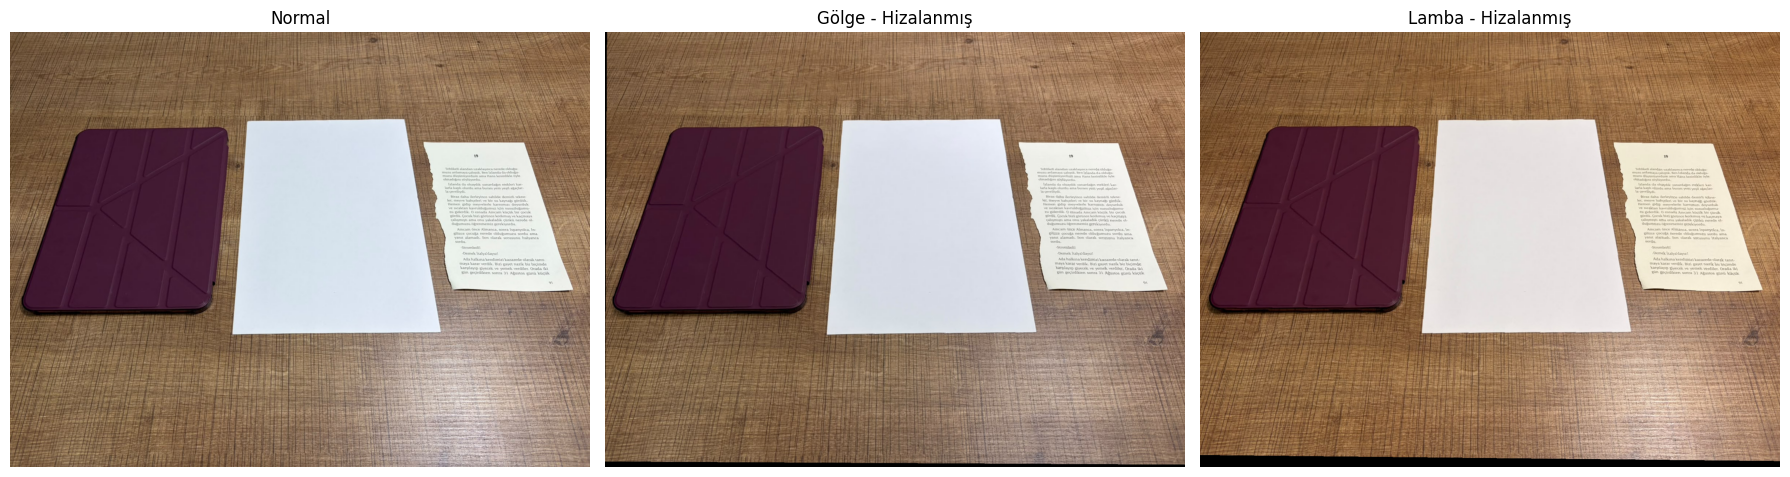

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

titles = ["Normal", "Gölge - Hizalanmış", "Lamba - Hizalanmış"]

results = [
    normal_aligned,
    golge_aligned,
    lamba_aligned
]

for ax, img, title in zip(axes, results, titles):

    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

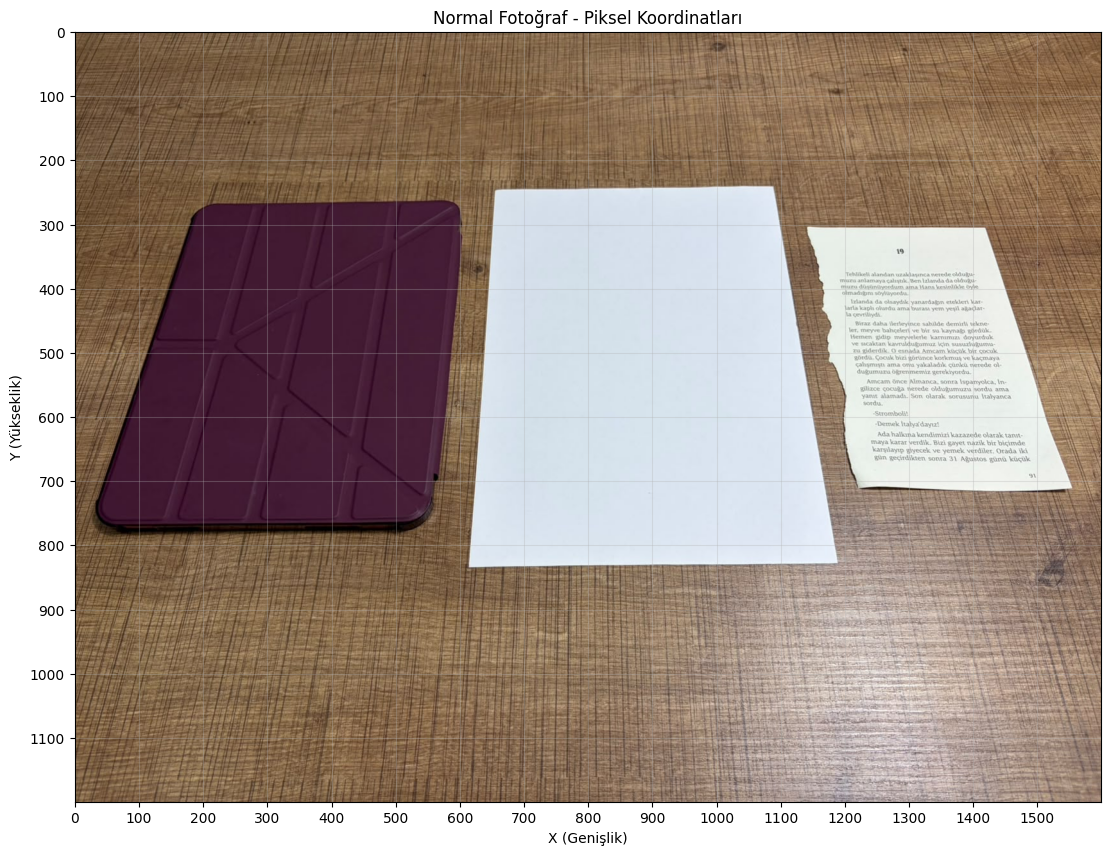

In [ ]:
#Fotoğrafı koordinat sistemiyle gösterme
plt.figure(figsize=(16, 10))

plt.imshow(
    cv2.cvtColor(normal_aligned, cv2.COLOR_BGR2RGB)
)

plt.title("Normal Fotoğraf - Piksel Koordinatları")

plt.xlabel("X (Genişlik)")
plt.ylabel("Y (Yükseklik)")

plt.xticks(np.arange(0, normal_aligned.shape[1], 100))
plt.yticks(np.arange(0, normal_aligned.shape[0], 100))

plt.grid(alpha=0.3)

plt.show()

In [ ]:
# Normal fotoğraf üzerinden belirlediğimiz koordinatlar

coordinates = {
    "P1": (220, 350),
    "P2": (280, 500),
    "P3": (330, 650)
}

In [ ]:
# Üç fotoğraftaki RGB değerlerini alma

aligned_images = {
    "Normal": normal_aligned,
    "Golge": golge_aligned,
    "Lamba": lamba_aligned
}

results = []

for image_name, img in aligned_images.items():

    # BGR -> RGB dönüşümü
    rgb_img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    for point_name, (x, y) in coordinates.items():

        # Pikselin RGB değerlerini al
        R, G, B = rgb_img[y, x]

        results.append({
            "Fotoğraf": image_name,
            "Piksel": point_name,
            "X": x,
            "Y": y,
            "R": int(R),
            "G": int(G),
            "B": int(B)
        })

pixel_df = pd.DataFrame(results)

display(pixel_df)

,Fotoğraf,Piksel,X,Y,R,G,B
0,Normal,P1,220,350,65,25,49
1,Normal,P2,280,500,66,26,50
2,Normal,P3,330,650,67,27,51
3,Golge,P1,220,350,64,25,46
4,Golge,P2,280,500,65,23,45
5,Golge,P3,330,650,63,24,45
6,Lamba,P1,220,350,70,23,41
7,Lamba,P2,280,500,75,26,45
8,Lamba,P3,330,650,73,26,44


In [ ]:
# Gölge fotoğrafını BGR olarak al
bgr_img = golge_aligned

# BGR -> RGB dönüşümü
rgb_img = cv2.cvtColor(
    bgr_img,
    cv2.COLOR_BGR2RGB
)

# Aynı koordinattaki pikseli al
x, y = coordinates["P1"]

# Dönüşüm öncesi
bgr_pixel = bgr_img[y, x]

# Dönüşüm sonrası
rgb_pixel = rgb_img[y, x]

for name, img in aligned_images.items():

    # BGR -> RGB
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    x, y = coordinates["P1"]

    bgr_value = img[y, x]
    rgb_value = rgb[y, x]

    print(f"\n--- {name} ---")
    print("BGR:", bgr_value)
    print("RGB:", rgb_value)


--- Normal ---
BGR: [49 25 65]
RGB: [65 25 49]

--- Golge ---
BGR: [46 25 64]
RGB: [64 25 46]

--- Lamba ---
BGR: [41 23 70]
RGB: [70 23 41]


HEDEF 2

**Tahmin:** Gölgede R, G ve B değerleri birlikte düşeceği için sabit RGB maskesinin alan oranı küçülecek; HSV maskesi ton (H) kanalı ışıktan daha az etkilendiği için daha kararlı kalacak. Lambada ise turuncu-kahve masa yüzeyinin R'si artacağı için RGB maskesinde nesne dışına taşma olmasını bekliyorum.

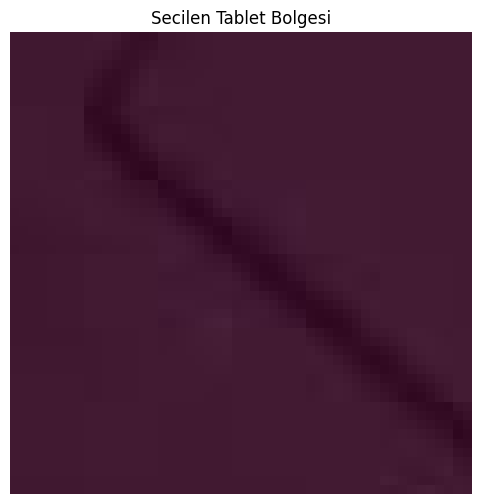

In [ ]:
# Normal ışıklı fotoğrafta seçilen bölge

x1, y1 = 240, 480
x2, y2 = 290, 530

# Seçilen küçük bölge
roi = normal_aligned[y1:y2, x1:x2]

# RGB'ye dönüştür
roi_rgb = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(roi_rgb)
plt.title("Secilen Tablet Bolgesi")
plt.axis("off")
plt.show()

In [ ]:
#ROI bölgesinin RGB ve HSV değerleri

# Seçilen bölgenin RGB değerleri
roi_rgb_pixels = roi_rgb.reshape(-1, 3)

# RGB kanal değerleri
rgb_min = roi_rgb_pixels.min(axis=0)
rgb_max = roi_rgb_pixels.max(axis=0)

print("RGB minimum:", rgb_min)
print("RGB maksimum:", rgb_max)


# HSV dönüşümü
roi_hsv = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)

roi_hsv_pixels = roi_hsv.reshape(-1, 3)

hsv_min = roi_hsv_pixels.min(axis=0)
hsv_max = roi_hsv_pixels.max(axis=0)

print("\nHSV minimum:", hsv_min)
print("HSV maksimum:", hsv_max)

RGB minimum: [46  6 30]
RGB maksimum: [72 32 58]

HSV minimum: [161 142  46]
HSV maksimum: [162 222  72]


In [ ]:
# RGB EŞİKLERİ
rgb_lower = np.percentile(roi_rgb_pixels, 5, axis=0)
rgb_upper = np.percentile(roi_rgb_pixels, 95, axis=0)

# RGB toleranslarını biraz genişletiyoruz
rgb_lower = np.clip(rgb_lower - 15, 0, 255).astype(np.uint8)
rgb_upper = np.clip(rgb_upper + 15, 0, 255).astype(np.uint8)


# HSV EŞİKLERİ
hsv_lower = np.percentile(roi_hsv_pixels, 5, axis=0)
hsv_upper = np.percentile(roi_hsv_pixels, 95, axis=0)

# HSV Toleransları:
# H (Renk Özü): +-8 (Renk kaymalarını tolere eder)
# S (Doygunluk): +-40 (Işık değişiminde doygunluk farklarını yakalar)
# V (Parlaklık): Alt sınırı -40 düşür, üst sınırı yüksek tut
hsv_lower = np.clip(
    hsv_lower - np.array([8, 40, 40]), 0, [179, 255, 255]
).astype(np.uint8)

hsv_upper = np.clip(
    hsv_upper + np.array([8, 40, 180]), 0, [179, 255, 255]
).astype(np.uint8)

# Lamba parlamasında maskenin çökmemesi için
# HSV üst sınırındaki V (Parlaklık) kanalını doğrudan maksimuma (255) sabitliyoruz.
hsv_upper[2] = 255



print("SABİTLENEN RGB EŞİKLERİ")
print("Alt sınır:", rgb_lower)
print("Üst sınır:", rgb_upper)

print("\nSABİTLENEN HSV EŞİKLERİ")
print("Alt sınır:", hsv_lower)
print("Üst sınır:", hsv_upper)

SABİTLENEN RGB EŞİKLERİ
Alt sınır: [37  0 22]
Üst sınır: [82 42 66]

SABİTLENEN HSV EŞİKLERİ
Alt sınır: [153 112  12]
Üst sınır: [170 236 255]


In [ ]:
#Aynı eşikleri üç fotoğrafa uygulama, altı maskeyi oluşturma

aligned_images = {
    "Normal": normal_aligned,
    "Golge": golge_aligned,
    "Lamba": lamba_aligned
}

masks = {}

for name, img in aligned_images.items():

    # BGR -> RGB
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # BGR -> HSV
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    # RGB maskesi
    rgb_mask = cv2.inRange(
        rgb,
        rgb_lower,
        rgb_upper
    )

    # HSV maskesi
    hsv_mask = cv2.inRange(
        hsv,
        hsv_lower,
        hsv_upper
    )

    masks[name] = {
        "RGB": rgb_mask,
        "HSV": hsv_mask
    }

print("Altı maske başarıyla oluşturuldu.")

Altı maske başarıyla oluşturuldu.


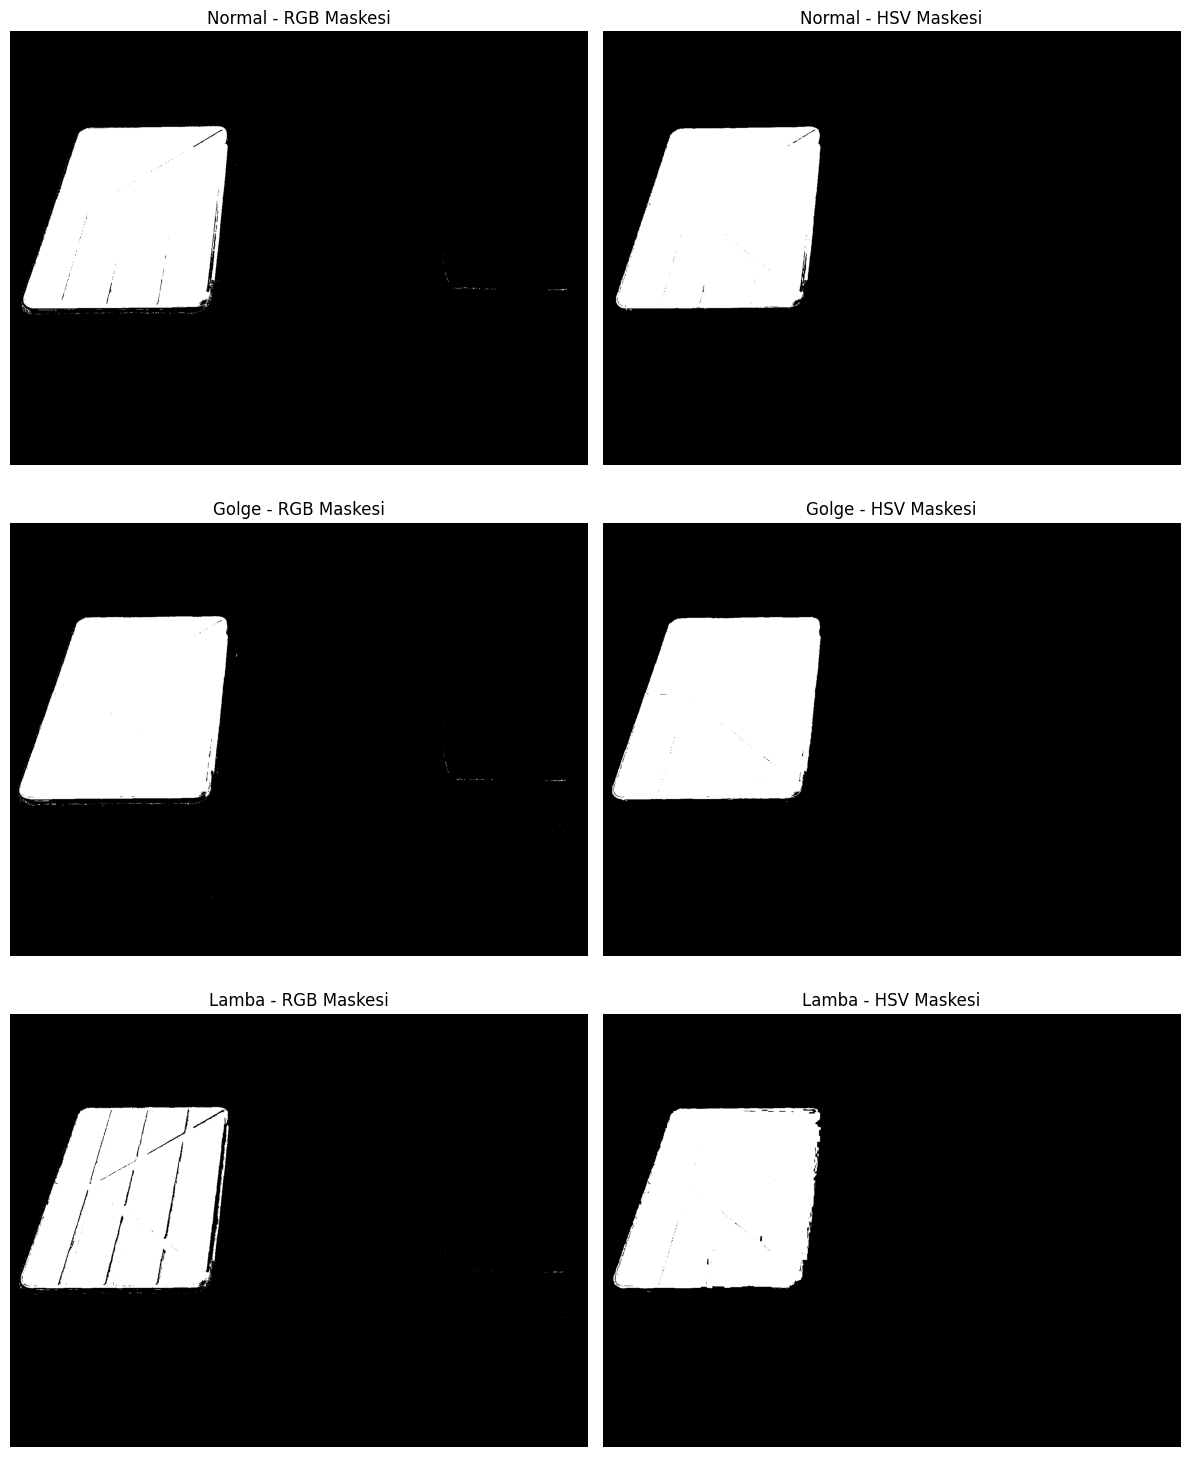

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(12, 15))

for row, (name, mask_data) in enumerate(masks.items()):

    axes[row, 0].imshow(mask_data["RGB"], cmap="gray")
    axes[row, 0].set_title(f"{name} - RGB Maskesi")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(mask_data["HSV"], cmap="gray")
    axes[row, 1].set_title(f"{name} - HSV Maskesi")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Seçilen piksel sayısının görüntü alanına oranını hesaplama

area_results = []

for image_name, mask_data in masks.items():

    for color_space, mask in mask_data.items():

        # Toplam piksel sayısı
        total_pixels = mask.size

        # Beyaz piksel sayısı
        selected_pixels = cv2.countNonZero(mask)

        # Görüntü alanına oranı
        area_ratio = (
            selected_pixels / total_pixels
        ) * 100

        area_results.append({
            "Fotoğraf": image_name,
            "Renk Uzayı": color_space,
            "Seçilen Piksel": selected_pixels,
            "Toplam Piksel": total_pixels,
            "Alan Oranı (%)": round(area_ratio, 3)
        })

area_df = pd.DataFrame(area_results)

display(area_df)

,Fotoğraf,Renk Uzayı,Seçilen Piksel,Toplam Piksel,Alan Oranı (%)
0,Normal,RGB,232569,1920000,12.113
1,Normal,HSV,232899,1920000,12.130
2,Golge,RGB,240031,1920000,12.502
3,Golge,HSV,238587,1920000,12.426
4,Lamba,RGB,226096,1920000,11.776
5,Lamba,HSV,232070,1920000,12.087


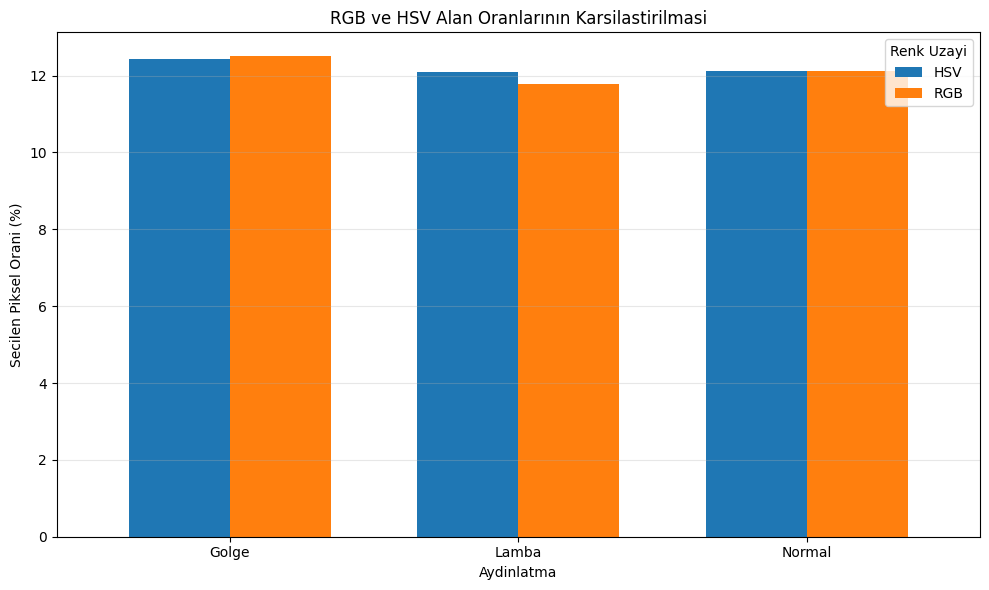

In [ ]:
#Alan oranlarını grafikle karşılaştırma

pivot_df = area_df.pivot(
    index="Fotoğraf",
    columns="Renk Uzayı",
    values="Alan Oranı (%)"
)

pivot_df.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.7
)

plt.title("RGB ve HSV Alan Oranlarının Karsilastirilmasi")
plt.xlabel("Aydinlatma")
plt.ylabel("Secilen Piksel Orani (%)")
plt.xticks(rotation=0)
plt.legend(title="Renk Uzayi")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

HEDEF 3

**Tahmin:**Parlaklık kaydırmasında ($b=+40$) tüm piksellerin değeri artacağından genel ortalama yükselecektir; ancak 255 değerinde kırpılan (doyuma ulaşan) pikseller nedeniyle ortalama artışı net +40'ın altında kalabilir. Gama dönüşümünde $\gamma=0.5$ karanlık ve orta tonları açarak ortalamayı yükseltirken, $\gamma=2.0$ piksel değerlerini üssel küçülterek görüntüyü karartacak ve ortalamayı düşürecektir.

In [ ]:
# Normal ışıklı görüntüyü kullanıyoruz
# OpenCV görüntüyü BGR formatında okur.
normal_rgb = cv2.cvtColor(normal_aligned, cv2.COLOR_BGR2RGB)

# Görüntüyü float32 veri tipine dönüştürüyoruz.
normal_float = normal_rgb.astype(np.float32)

# Orijinal görüntünün ortalamasını hesaplıyoruz.
original_mean = np.mean(normal_float)

print("Görüntü boyutu:", normal_rgb.shape)
print("Veri tipi:", normal_rgb.dtype)
print("Orijinal görüntü ortalaması:", original_mean)

Görüntü boyutu: (1200, 1600, 3)
Veri tipi: uint8
Orijinal görüntü ortalaması: 131.43459


In [ ]:
# 1. Parlaklık kaydırma fonksiyonu
def brightness_shift(image, b=40):
    image_float = image.astype(np.float32)

    result = image_float + b

    result = np.clip(result, 0, 255)

    return result


# 2. Gama dönüşümü fonksiyonu
def gamma_transform(image, gamma):
    image_float = image.astype(np.float32)

    result = 255 * ((image_float / 255) ** gamma)

    result = np.clip(result, 0, 255)

    return result

In [ ]:
# Parlaklık artırma
bright_image = brightness_shift(normal_float, b=40)

# Gama dönüşümü: gamma = 0.5
gamma_05_image = gamma_transform(normal_float, gamma=0.5)

# Gama dönüşümü: gamma = 2.0
gamma_2_image = gamma_transform(normal_float, gamma=2.0)

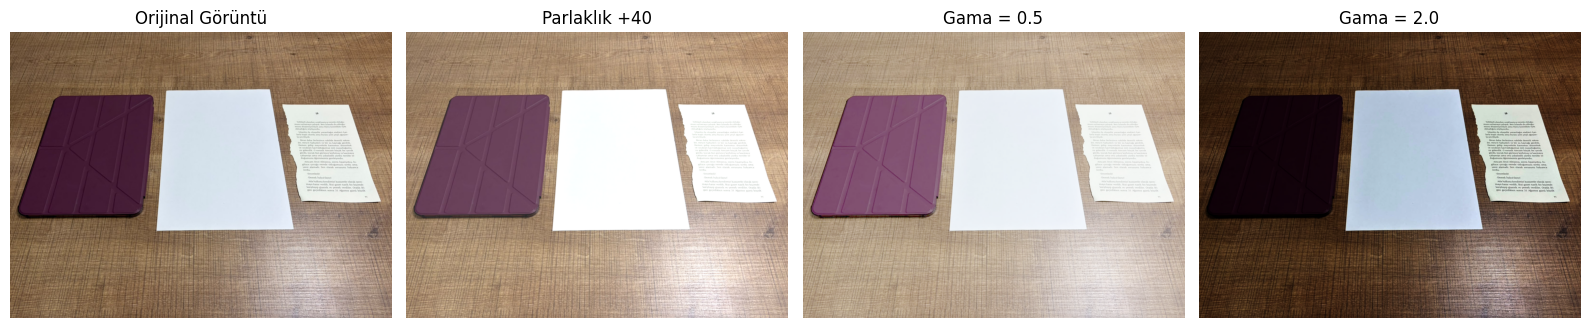

In [ ]:
images = [
    normal_float,
    bright_image,
    gamma_05_image,
    gamma_2_image
]

titles = [
    "Orijinal Görüntü",
    "Parlaklık +40",
    "Gama = 0.5",
    "Gama = 2.0"
]

plt.figure(figsize=(16, 5))

for i in range(4):
    plt.subplot(1, 4, i + 1)

    plt.imshow(np.clip(images[i], 0, 255).astype(np.uint8))
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Her görüntünün ortalamasını hesapla
original_mean = np.mean(normal_float)
bright_mean = np.mean(bright_image)
gamma_05_mean = np.mean(gamma_05_image)
gamma_2_mean = np.mean(gamma_2_image)

print("Orijinal görüntü ortalaması:", original_mean)
print("Parlaklık +40 sonrası ortalama:", bright_mean)
print("Gama 0.5 sonrası ortalama:", gamma_05_mean)
print("Gama 2.0 sonrası ortalama:", gamma_2_mean)

Orijinal görüntü ortalaması: 131.43459
Parlaklık +40 sonrası ortalama: 168.2374
Gama 0.5 sonrası ortalama: 177.02742
Gama 2.0 sonrası ortalama: 83.84147


In [ ]:
# 40 eklendiğinde 255'i aşacak pikseller
clipped_mask = normal_float > 215

# Kırpılan piksel sayısı
clipped_count = np.count_nonzero(clipped_mask)

# Toplam piksel sayısı (kanallar dahil)
total_values = normal_float.size

# Kırpılma oranı
clipped_ratio = (clipped_count / total_values) * 100

print("255'te kırpılan kanal değeri sayısı:", clipped_count)
print("Toplam kanal değeri sayısı:", total_values)
print("Kırpılma oranı (%):", clipped_ratio)

255'te kırpılan kanal değeri sayısı: 1089408
Toplam kanal değeri sayısı: 5760000
Kırpılma oranı (%): 18.91333333333333


HEDEF 4

**Tahmin:** Yazı satırları arası yaklaşık 10–12 piksel olduğundan 1/4 küçültmede harfler 1–3 piksele inecek ve iki yöntemde de okunamayacak; en yakın komşu yöntemi bazı çizgileri kopararak yapay desen üretecek, alan ortalaması ise sahte desen üretmeden yazıyı griye çevirecek. Büyütme (en yakın komşu) yalnızca mevcut pikselleri tekrarlayacağı için kaybolan ayrıntıyı geri getirmeyecek.

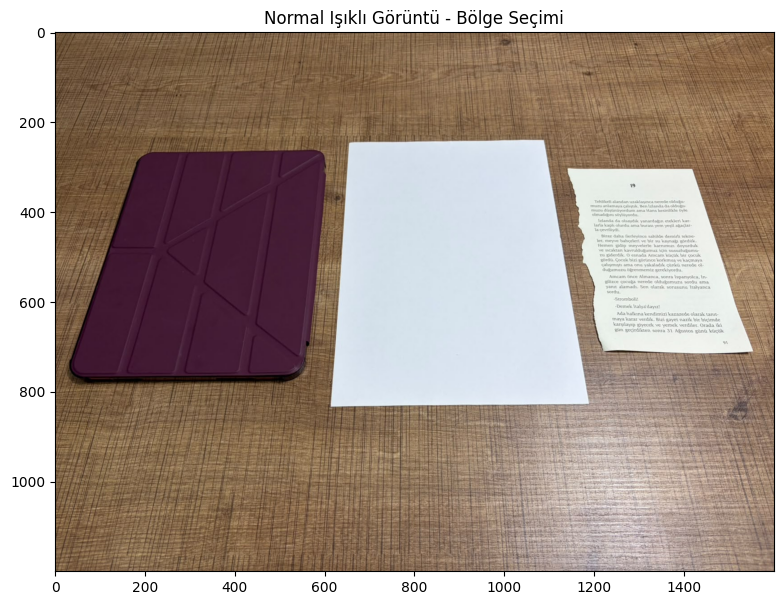

In [ ]:
# Normal ışıklı görüntüyü RGB formatına dönüştür
normal_rgb = cv2.cvtColor(normal_aligned, cv2.COLOR_BGR2RGB)

# Görüntüyü göster
plt.figure(figsize=(10, 7))
plt.imshow(normal_rgb)
plt.title("Normal Işıklı Görüntü - Bölge Seçimi")
plt.axis("on")
plt.show()

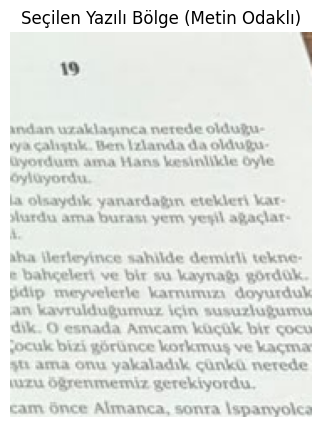

Kırpılan bölgenin boyutu: (230, 180, 3)


In [ ]:
# Sağ taraftaki yazılı kağıdın (metin alanının) koordinatları
x1, y1 = 1250, 320  # Sol üst köşe
x2, y2 = 1430, 550  # Sağ alt köşe

# Görüntüyü kırp (y1:y2 satırlar, x1:x2 sütunlar)
crop = normal_rgb[y1:y2, x1:x2]

# Kırpılan bölgeyi göster
plt.figure(figsize=(8, 5))
plt.imshow(crop)
plt.title("Seçilen Yazılı Bölge (Metin Odaklı)")
plt.axis("off")
plt.show()

print("Kırpılan bölgenin boyutu:", crop.shape)

In [ ]:
# Görüntünün mevcut genişlik ve yüksekliğini al
height, width = crop.shape[:2]

# Yeni boyutları hesapla
new_width = width // 4
new_height = height // 4

# 1. En yakın komşu yöntemiyle küçültme
small_nearest = cv2.resize(
    crop,
    (new_width, new_height),
    interpolation=cv2.INTER_NEAREST
)

# 2. Alan ortalaması yöntemiyle küçültme
small_area = cv2.resize(
    crop,
    (new_width, new_height),
    interpolation=cv2.INTER_AREA
)

print("Orijinal boyut:", crop.shape)
print("Küçültülmüş boyut:", small_nearest.shape)

Orijinal boyut: (230, 180, 3)
Küçültülmüş boyut: (57, 45, 3)


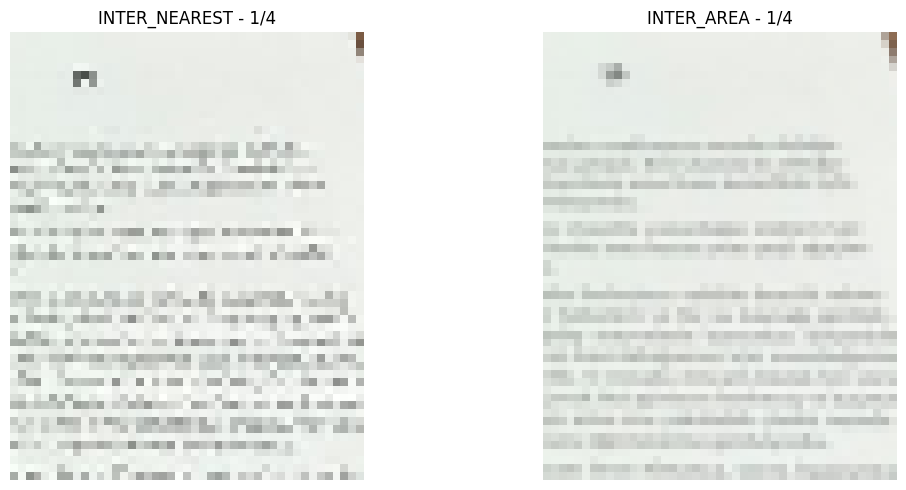

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(small_nearest)
plt.title("INTER_NEAREST - 1/4")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(small_area)
plt.title("INTER_AREA - 1/4")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# En yakın komşu ile küçültülmüş görüntüyü büyüt
nearest_up = cv2.resize(
    small_nearest,
    (width, height),
    interpolation=cv2.INTER_NEAREST
)

# Alan ortalaması ile küçültülmüş görüntüyü
# en yakın komşu yöntemiyle büyüt
area_up = cv2.resize(
    small_area,
    (width, height),
    interpolation=cv2.INTER_NEAREST
)

print("Büyütülmüş görüntü boyutu:", nearest_up.shape)

Büyütülmüş görüntü boyutu: (230, 180, 3)


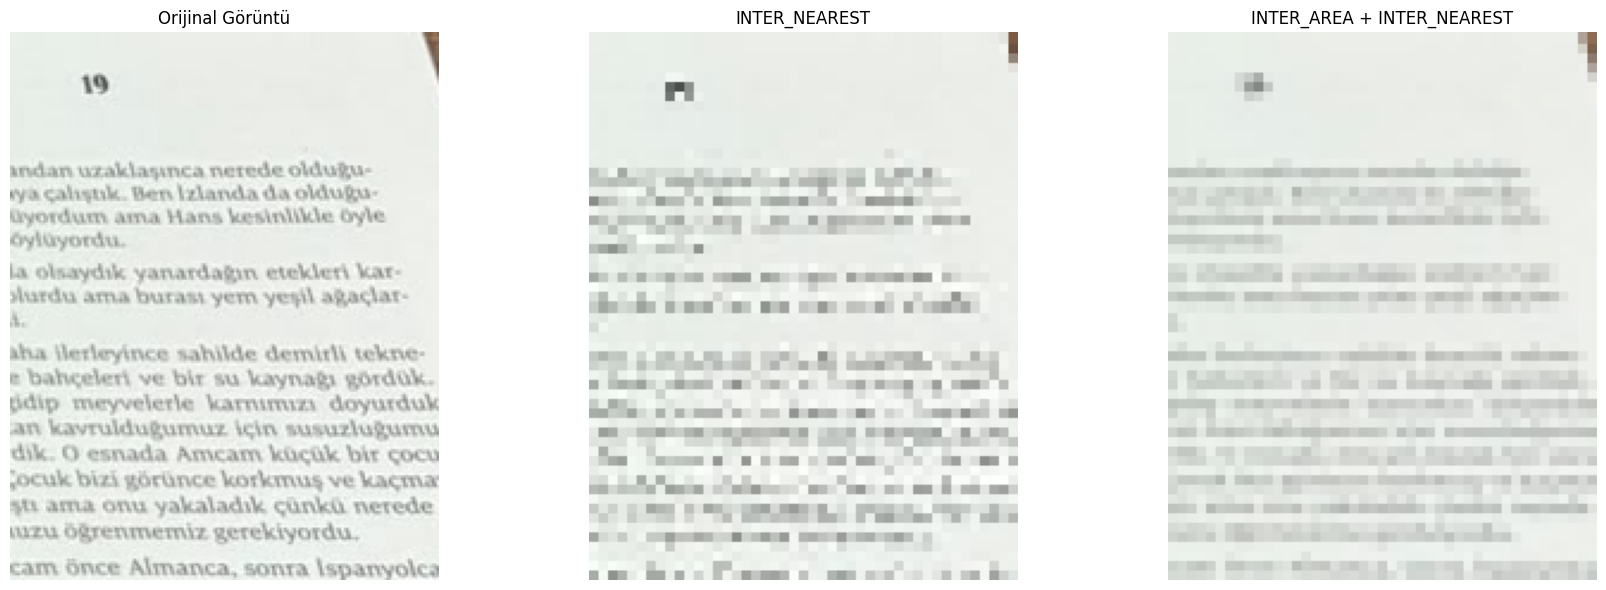

In [ ]:
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(crop)
plt.title("Orijinal Görüntü")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(nearest_up)
plt.title("INTER_NEAREST")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(area_up)
plt.title("INTER_AREA")
plt.axis("off")

plt.tight_layout()
plt.show()